In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

Resim başarıyla yüklendi!
HoughLines eşik değeri: 40


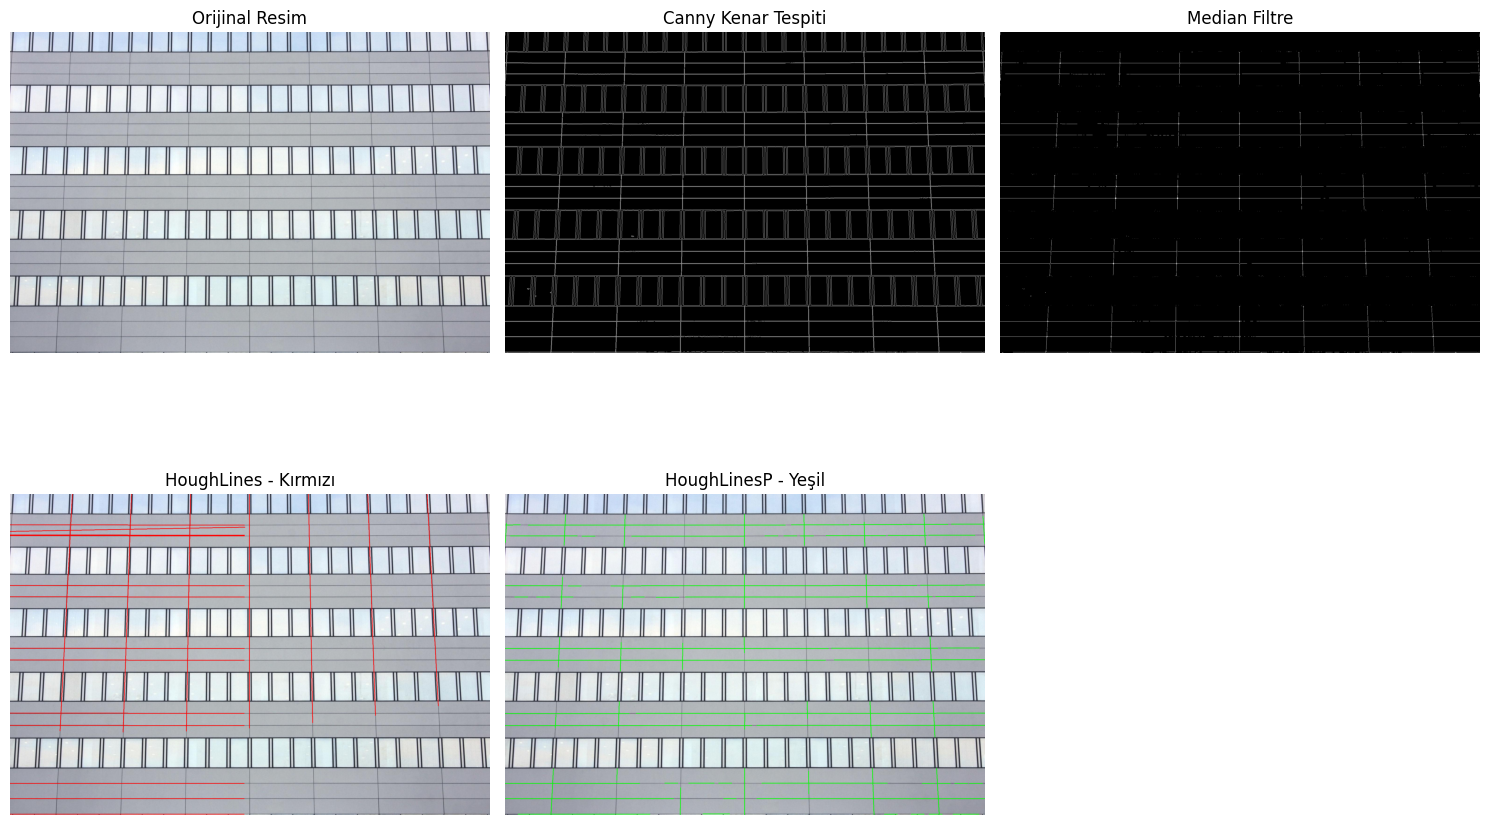

HoughLines doğru sayısı: 582
HoughLinesP doğru sayısı: 95


In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. RESMİ OKU
resim_yolu = "/content/resim.jpg.avif"

img = cv2.imread(resim_yolu)

if img is None:
    pil_img = Image.open(resim_yolu).convert("RGB")
    img = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

print("Resim başarıyla yüklendi!")

hough_img = img.copy()
houghp_img = img.copy()

# 2. GRİ TONLAMA
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 3. CANNY
edges = cv2.Canny(gray, 50, 150)

# 4. MEDIAN FİLTRE
median = cv2.medianBlur(edges, 3)

# 5. HOUGH LINES
lines = None

for threshold in [40, 30, 20, 10, 5]:
    lines = cv2.HoughLines(
        median,
        1,
        np.pi / 180,
        threshold
    )

    if lines is not None:
        print("HoughLines eşik değeri:", threshold)
        break

if lines is not None:
    for line in lines[:20]:
        rho, theta = line[0]

        a = np.cos(theta)
        b = np.sin(theta)

        x0 = a * rho
        y0 = b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)

        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)

        cv2.line(
            hough_img,
            (x1, y1),
            (x2, y2),
            (0, 0, 255),
            2
        )

# 6. HOUGH LINES P
linesP = cv2.HoughLinesP(
    median,
    1,
    np.pi / 180,
    50,
    minLineLength=50,
    maxLineGap=10
)

if linesP is not None:
    for line in linesP:
        x1, y1, x2, y2 = line[0]

        cv2.line(
            houghp_img,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

# 7. SONUÇLARI GÖSTER
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Resim")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Kenar Tespiti")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(median, cmap="gray")
plt.title("Median Filtre")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(cv2.cvtColor(hough_img, cv2.COLOR_BGR2RGB))
plt.title("HoughLines - Kırmızı")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(cv2.cvtColor(houghp_img, cv2.COLOR_BGR2RGB))
plt.title("HoughLinesP - Yeşil")
plt.axis("off")

plt.tight_layout()
plt.show()

print("HoughLines doğru sayısı:",
      0 if lines is None else len(lines))

print("HoughLinesP doğru sayısı:",
      0 if linesP is None else len(linesP))
